# Prepare physics inputs from the two datasets

This notebook inspects the raw files before physics-based signal generation. It checks channel structure, row length, numeric ranges, available labels, and operating conditions.

The raw datasets remain unchanged. Summaries are written to `data/processed/physics_inputs/`. Current measurements and units are detected from the files rather than assumed.

In [1]:
%pip install -q pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_dir = Path.cwd()
if not (project_dir / 'data').exists():
    project_dir = project_dir.parent

raw_dir = project_dir / 'data' / 'raw'
output_dir = project_dir / 'data' / 'processed' / 'physics_inputs'
output_dir.mkdir(parents=True, exist_ok=True)

motor_dir = raw_dir / 'induction_motor'
gearbox_dir = raw_dir / 'gearbox'
assert motor_dir.exists(), f'Missing {motor_dir}'
assert gearbox_dir.exists(), f'Missing {gearbox_dir}'

motor_columns = [
    'tachometer',
    'underhang_axial', 'underhang_radial', 'underhang_tangential',
    'overhang_axial', 'overhang_radial', 'overhang_tangential',
    'microphone',
]

def signal_files(folder):
    return sorted(file for file in folder.rglob('*') if file.suffix.lower() in {'.csv', '.txt'})

def read_signal(file, rows=5_000):
    frame = pd.read_csv(file, sep=r'[\s,;]+', engine='python', header=None, nrows=rows)
    return frame.apply(pd.to_numeric, errors='coerce').dropna(how='all')

def row_count(file):
    total = sum(1 for _ in file.open('r', encoding='utf-8', errors='ignore'))
    first = pd.read_csv(file, sep=r'[\s,;]+', engine='python', header=None, nrows=1)
    first_numeric = pd.to_numeric(first.iloc[0], errors='coerce').notna().any()
    return total if first_numeric else total - 1

def names_for(frame, expected):
    return expected if frame.shape[1] == len(expected) else [f'channel_{i}' for i in range(frame.shape[1])]

def motor_condition(file):
    text = str(file.relative_to(motor_dir)).lower()
    labels = [
        ('normal', 'normal'), ('imbalance', 'imbalance'),
        ('horizontal', 'horizontal_misalignment'), ('vertical', 'vertical_misalignment'),
        ('inner', 'inner_bearing'), ('outer', 'outer_bearing'),
    ]
    return next((label for key, label in labels if key in text), 'unknown')

def motor_load(file):
    match = re.search(r'(\d+(?:\.\d+)?)g', str(file.relative_to(motor_dir)).lower())
    return float(match.group(1)) if match else None

def gearbox_condition(file):
    text = str(file.relative_to(gearbox_dir)).lower()
    if file.stem.lower().startswith('b') or 'broken' in text:
        return 'broken_tooth'
    if file.stem.lower().startswith('h') or 'healthy' in text:
        return 'healthy'
    return 'unknown'

def gearbox_load(file):
    match = re.search(r'hz(\d+)', file.stem.lower())
    return int(match.group(1)) if match else None

def gearbox_speed(file):
    match = re.search(r'(\d+(?:\.\d+)?)hz', file.stem.lower())
    return float(match.group(1)) if match else None

## 1. Induction-motor dataset — channels, units, and length

In [3]:
motor_files = signal_files(motor_dir)
assert motor_files, f'No motor signal files found in {motor_dir}'

motor_rows = []
for file in motor_files:
    sample = read_signal(file, rows=2_000)
    channels = names_for(sample, motor_columns)
    motor_rows.append({
        'dataset': 'induction_motor',
        'source_file': str(file.relative_to(motor_dir)),
        'health_state': motor_condition(file),
        'load_raw_g': motor_load(file),
        'rows': row_count(file),
        'channels': len(channels),
        'channel_names': '|'.join(channels),
        'units': 'not provided in raw file',
        'size_mb': round(file.stat().st_size / 1_000_000, 2),
    })

motor_manifest = pd.DataFrame(motor_rows)
display(motor_manifest.head())
display(motor_manifest.groupby('health_state').agg(files=('source_file', 'size'), rows=('rows', 'sum')))
print(f'Files: {len(motor_manifest)} | Channels in first file: {motor_manifest.iloc[0].channels}')

motor_sample = read_signal(motor_files[0])
motor_sample.columns = names_for(motor_sample, motor_columns)
current_names = {'ia', 'ib', 'ic', 'i_a', 'i_b', 'i_c', 'motor_current'}
current_channels = [
    column for column in motor_sample.columns
    if 'current' in column.lower() or 'ampere' in column.lower() or column.lower() in current_names
]
print('Current channels found:', current_channels or 'none')
if not current_channels:
    print('The downloaded motor files do not contain current measurements; current must be added or simulated later.')

display(motor_sample.describe().T[['count', 'mean', 'std', 'min', 'max']])

,dataset,source_file,health_state,load_raw_g,rows,channels,channel_names,units,size_mb
0,induction_motor,imbalance\imbalance\10g\13.9264.csv,imbalance,10.0,250000,8,tachometer|underhang_axial|underhang_radial|un...,not provided in raw file,17.58
1,induction_motor,imbalance\imbalance\10g\14.5408.csv,imbalance,10.0,250000,8,tachometer|underhang_axial|underhang_radial|un...,not provided in raw file,17.58
2,induction_motor,imbalance\imbalance\10g\15.7696.csv,imbalance,10.0,250000,8,tachometer|underhang_axial|underhang_radial|un...,not provided in raw file,17.56
3,induction_motor,imbalance\imbalance\10g\16.5888.csv,imbalance,10.0,250000,8,tachometer|underhang_axial|underhang_radial|un...,not provided in raw file,17.58
4,induction_motor,imbalance\imbalance\10g\17.2032.csv,imbalance,10.0,250000,8,tachometer|underhang_axial|underhang_radial|un...,not provided in raw file,17.42


,files,rows
health_state,,
imbalance,333,83250000
normal,49,12250000


Files: 382 | Channels in first file: 8
Current channels found: none
The downloaded motor files do not contain current measurements; current must be added or simulated later.


,count,mean,std,min,max
tachometer,5000.0,0.251262,1.867224,-1.132100,5.093000
underhang_axial,5000.0,0.000424,1.254570,-3.709900,1.951900
underhang_radial,5000.0,-0.004276,0.346475,-1.706600,0.581200
underhang_tangential,5000.0,0.002252,0.047664,-0.168250,0.145130
overhang_axial,5000.0,0.105588,0.123758,-0.230190,0.315160
overhang_radial,5000.0,0.019061,0.033639,-0.081946,0.097455
overhang_tangential,5000.0,0.351336,0.789180,-1.183200,1.862700
microphone,5000.0,0.017487,0.125006,-0.238050,0.540160


## 2. Gearbox dataset — four vibration channels and load groups

In [4]:
gearbox_files = signal_files(gearbox_dir)
assert gearbox_files, f'No gearbox signal files found in {gearbox_dir}'

gearbox_rows = []
for file in gearbox_files:
    sample = read_signal(file, rows=2_000)
    channels = names_for(sample, ['a1', 'a2', 'a3', 'a4'])
    gearbox_rows.append({
        'dataset': 'gearbox',
        'source_file': str(file.relative_to(gearbox_dir)),
        'health_state': gearbox_condition(file),
        'rotational_condition_hz': gearbox_speed(file),
        'load_percent': gearbox_load(file),
        'rows': row_count(file),
        'channels': len(channels),
        'channel_names': '|'.join(channels),
        'units': 'not provided in raw file',
        'size_mb': round(file.stat().st_size / 1_000_000, 2),
    })

gearbox_manifest = pd.DataFrame(gearbox_rows)
display(gearbox_manifest.head())
display(gearbox_manifest.groupby(['health_state', 'load_percent']).agg(files=('source_file', 'size'), rows=('rows', 'sum')).reset_index())
print(f'Files: {len(gearbox_manifest)} | Rotational condition values: {sorted(gearbox_manifest.rotational_condition_hz.dropna().unique())}')

gearbox_sample = read_signal(gearbox_files[0])
gearbox_sample.columns = names_for(gearbox_sample, ['a1', 'a2', 'a3', 'a4'])
display(gearbox_sample.describe().T[['count', 'mean', 'std', 'min', 'max']])

,dataset,source_file,health_state,rotational_condition_hz,load_percent,rows,channels,channel_names,units,size_mb
0,gearbox,BrokenTooth\b30hz0.csv,broken_tooth,30.0,0,88320,4,a1|a2|a3|a4,not provided in raw file,3.08
1,gearbox,BrokenTooth\b30hz10.csv,broken_tooth,30.0,10,111616,4,a1|a2|a3|a4,not provided in raw file,3.89
2,gearbox,BrokenTooth\b30hz20.csv,broken_tooth,30.0,20,114432,4,a1|a2|a3|a4,not provided in raw file,3.97
3,gearbox,BrokenTooth\b30hz30.csv,broken_tooth,30.0,30,89856,4,a1|a2|a3|a4,not provided in raw file,3.11
4,gearbox,BrokenTooth\b30hz40.csv,broken_tooth,30.0,40,94464,4,a1|a2|a3|a4,not provided in raw file,3.26


,health_state,load_percent,files,rows
0,broken_tooth,0,1,88320
1,broken_tooth,10,1,111616
2,broken_tooth,20,1,114432
3,broken_tooth,30,1,89856
4,broken_tooth,40,1,94464
5,broken_tooth,50,1,94208
6,broken_tooth,60,1,95488
7,broken_tooth,70,1,100864
8,broken_tooth,80,1,110335
9,broken_tooth,90,1,105728


Files: 20 | Rotational condition values: [np.float64(30.0)]


,count,mean,std,min,max
a1,4999.0,0.012578,3.452386,-16.3548,19.0489
a2,4999.0,0.020714,3.803655,-16.5693,15.5054
a3,4999.0,0.020088,3.060870,-11.4722,15.4648
a4,4999.0,-0.077104,3.319090,-18.8941,14.3429


## 3. Representative signal statistics for calibration

,dataset,source_file,channel,sample_rows,mean,std,rms,peak_to_peak,max_abs
0,induction_motor,D:\P-SYNTH Physics Guided Synthetic Maintenanc...,tachometer,5000,0.251262,1.867037,1.883869,6.225100,5.093000
1,induction_motor,D:\P-SYNTH Physics Guided Synthetic Maintenanc...,underhang_axial,5000,0.000424,1.254444,1.254444,5.661800,3.709900
2,induction_motor,D:\P-SYNTH Physics Guided Synthetic Maintenanc...,underhang_radial,5000,-0.004276,0.346440,0.346467,2.287800,1.706600
3,induction_motor,D:\P-SYNTH Physics Guided Synthetic Maintenanc...,underhang_tangential,5000,0.002252,0.047659,0.047712,0.313380,0.168250
4,induction_motor,D:\P-SYNTH Physics Guided Synthetic Maintenanc...,overhang_axial,5000,0.105588,0.123746,0.162671,0.545350,0.315160
5,induction_motor,D:\P-SYNTH Physics Guided Synthetic Maintenanc...,overhang_radial,5000,0.019061,0.033635,0.038661,0.179401,0.097455
6,induction_motor,D:\P-SYNTH Physics Guided Synthetic Maintenanc...,overhang_tangential,5000,0.351336,0.789101,0.863781,3.045900,1.862700
7,induction_motor,D:\P-SYNTH Physics Guided Synthetic Maintenanc...,microphone,5000,0.017487,0.124994,0.126211,0.778210,0.540160
8,gearbox,D:\P-SYNTH Physics Guided Synthetic Maintenanc...,a1,4999,0.012578,3.452041,3.452064,35.403700,19.048900
9,gearbox,D:\P-SYNTH Physics Guided Synthetic Maintenanc...,a2,4999,0.020714,3.803274,3.803331,32.074700,16.569300


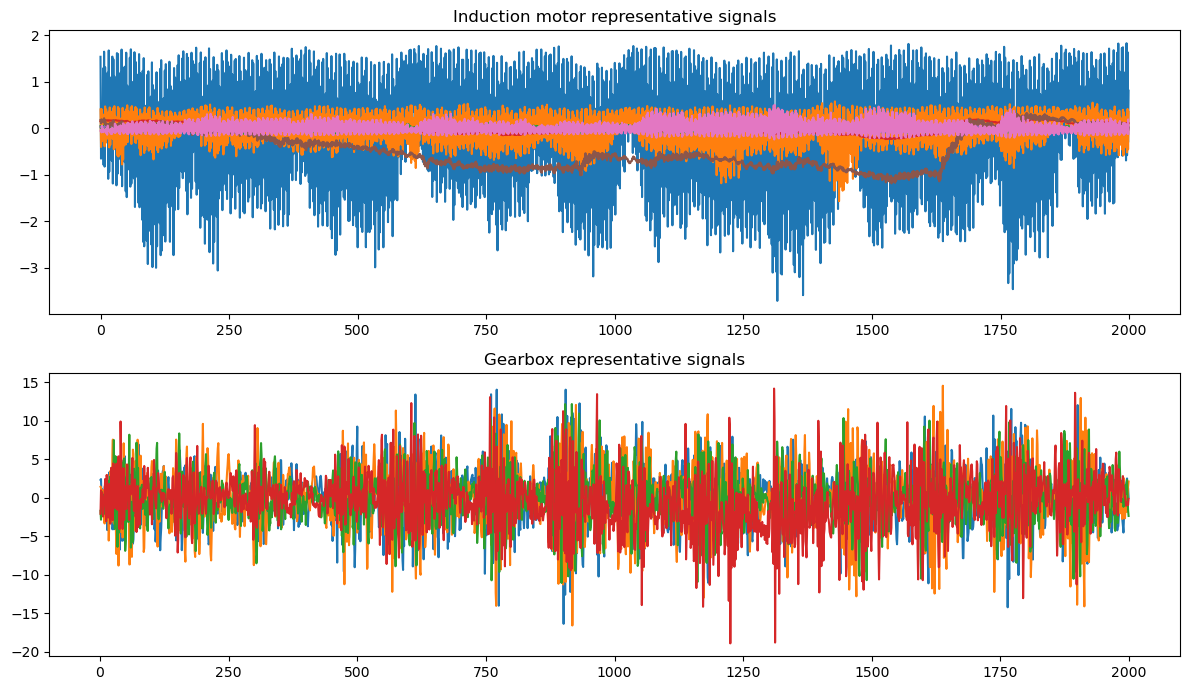

In [5]:
def signal_stats(file, dataset):
    frame = read_signal(file)
    expected = motor_columns if dataset == 'induction_motor' else ['a1', 'a2', 'a3', 'a4']
    frame.columns = names_for(frame, expected)
    rows = []
    for column in frame.columns:
        values = frame[column].to_numpy(dtype=float)
        values = values[np.isfinite(values)]
        rows.append({
            'dataset': dataset,
            'source_file': str(file),
            'channel': column,
            'sample_rows': len(values),
            'mean': values.mean(),
            'std': values.std(),
            'rms': np.sqrt(np.mean(values ** 2)),
            'peak_to_peak': values.max() - values.min(),
            'max_abs': np.abs(values).max(),
        })
    return pd.DataFrame(rows)

motor_representative = motor_files[0]
gearbox_representative = gearbox_files[0]
calibration = pd.concat([
    signal_stats(motor_representative, 'induction_motor'),
    signal_stats(gearbox_representative, 'gearbox'),
], ignore_index=True)
display(calibration)

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
motor_plot = read_signal(motor_representative, rows=2_000)
motor_plot.columns = names_for(motor_plot, motor_columns)
motor_plot.iloc[:, 1:].plot(ax=axes[0], legend=False, title='Induction motor representative signals')
gearbox_plot = read_signal(gearbox_representative, rows=2_000)
gearbox_plot.columns = names_for(gearbox_plot, ['a1', 'a2', 'a3', 'a4'])
gearbox_plot.plot(ax=axes[1], legend=False, title='Gearbox representative signals')
plt.tight_layout()
plt.show()

## 4. Save physics-input summaries

In [6]:
motor_manifest.to_csv(output_dir / 'induction_motor_manifest.csv', index=False)
gearbox_manifest.to_csv(output_dir / 'gearbox_manifest.csv', index=False)
calibration.to_csv(output_dir / 'representative_calibration.csv', index=False)

print(f'Saved summaries to: {output_dir}')
print('Use these summaries to set fault amplitudes, noise levels, load groups, and signal lengths in the generator.')

Saved summaries to: D:\P-SYNTH Physics Guided Synthetic Maintenance Data Generator\data\processed\physics_inputs
Use these summaries to set fault amplitudes, noise levels, load groups, and signal lengths in the generator.
